KMEANS

In [1]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Persiapan Data (Tanpa Label)
df = pd.DataFrame({
    'Pendapatan': [15, 20, np.nan, 80, 85, 90],
    'Skor_Belanja': [30, 40, 35, 90, 85, np.nan]
})

X = df[['Pendapatan', 'Skor_Belanja']]

# 2. Pipeline Preprocessing
preprocessor = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 3. Master Pipeline dengan K-Means (K=2)
master_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', KMeans(n_clusters=2, random_state=42, n_init='auto'))
])

# 4. Pelatihan & Prediksi Cluster
cluster_labels = master_pipeline.fit_predict(X)

print("Data Input Asli:\n", X)
print("\nHasil Pengelompokan (Cluster Label):\n", cluster_labels)

Data Input Asli:
    Pendapatan  Skor_Belanja
0        15.0          30.0
1        20.0          40.0
2         NaN          35.0
3        80.0          90.0
4        85.0          85.0
5        90.0           NaN

Hasil Pengelompokan (Cluster Label):
 [0 0 0 1 1 0]


In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

df = pd.DataFrame({
    'Panjang_cm': [10, 11, 10.5, 50, 52, 51],
    'Lebar_cm': [5, 5.5, 5.2, 25, 26, 25.5],
    'Berat_gr': [100, 110, 105, 500, 520, 510]
})

wcss = []
silhouette_scores = []
rentang_k = range(2, 6)

for k in rentang_k:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    label = model.fit_predict(df)
    wcss.append(model.inertia_)
    
    score = silhouette_score(df, label)
    silhouette_scores.append(score)

tabel_evaluasi = pd.DataFrame({
    'Jumlah K': rentang_k,
    'WCSS (Inertia)': wcss,
    'Silhouette Score': silhouette_scores
})

print("=== Hasil Evaluasi K-Means ===")
print(tabel_evaluasi)

=== Hasil Evaluasi K-Means ===
   Jumlah K  WCSS (Inertia)  Silhouette Score
0         2      253.126667          0.975300
1         3      101.251667          0.574999
2         4       50.626667          0.491560
3         5       12.645000          0.083535


Studi kasus kmeans

Jumlah Cluster Terbaik (K): 3 dengan Silhouette Score: 0.9034
    Usia  Pendapatan  Skor_Belanja  Segmen
0     19          15            30       2
1     21          16            35       2
2     20          15            32       2
3     23          18            40       2
4     58          80            15       0
5     60          85            10       0
6     62          82            12       0
7     55          78            18       0
8     30         120            90       1
9     32         130            95       1
10    31         125            88       1
11    35         140            92       1


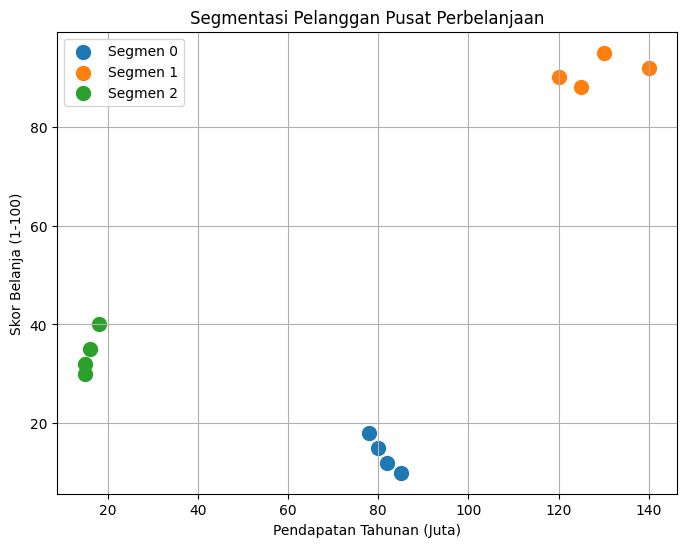

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

data_pelanggan = {
    'Usia': [19, 21, 20, 23, 58, 60, 62, 55, 30, 32, 31, 35],
    'Pendapatan': [15, 16, 15, 18, 80, 85, 82, 78, 120, 130, 125, 140],
    'Skor_Belanja': [30, 35, 32, 40, 15, 10, 12, 18, 90, 95, 88, 92]
}
df_pelanggan = pd.DataFrame(data_pelanggan)

preprocessor = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

df_scaled = preprocessor.fit_transform(df_pelanggan)

best_k = 1
best_score = 0
rentang_k = range(2, 6)

for k in rentang_k:
    model = KMeans(n_clusters=k, random_state=42, n_init='auto')
    label = model.fit_predict(df_scaled)
    score = silhouette_score(df_scaled, label)

    if score > best_score:
        best_score = score
        best_k = k

master_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', KMeans(n_clusters=best_k, random_state=42, n_init='auto'))
])

cluster_labels = master_pipeline.fit_predict(df_pelanggan)
df_pelanggan['Segmen'] = cluster_labels

print(f"Jumlah Cluster Terbaik (K): {best_k} dengan Silhouette Score: {best_score:.4f}")
print(df_pelanggan)

plt.figure(figsize=(8, 6))

for i in range(best_k):
    data_plot = df_pelanggan[df_pelanggan['Segmen'] == i]
    plt.scatter(data_plot['Pendapatan'], data_plot['Skor_Belanja'], 
                s=100, label=f'Segmen {i}')

plt.title('Segmentasi Pelanggan Pusat Perbelanjaan')
plt.xlabel('Pendapatan Tahunan (Juta)')
plt.ylabel('Skor Belanja (1-100)')
plt.legend()
plt.grid(True)
plt.show()

PCA

In [4]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.DataFrame({
    'Panjang_cm': [10, 11, 10.5, 50, 52, 51],
    'Lebar_cm': [5, 5.5, 5.2, 25, 26, 25.5],
    'Berat_gr': [100, 110, 105, 500, 520, 510]
})

# Pipeline: Skala data lalu kurangi dari 3 fitur menjadi 2 fitur
master_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2))
])

# Eksekusi transformasi
data_direduksi = master_pipeline.fit_transform(df)
pca_model = master_pipeline.named_steps['pca']

print("Dimensi Awal:", df.shape)
print("Dimensi Setelah PCA:", data_direduksi.shape)
print("Data Setelah PCA:\n", data_direduksi)
print("\nRasio Informasi yang Dipertahankan:", pca_model.explained_variance_ratio_)

Dimensi Awal: (6, 3)
Dimensi Setelah PCA: (6, 2)
Data Setelah PCA:
 [[-1.77295535e+00 -1.35886604e-03]
 [-1.68748885e+00 -1.32572164e-03]
 [-1.73306942e+00  2.68442544e-03]
 [ 1.64570471e+00 -3.30903130e-05]
 [ 1.81663771e+00  3.31984732e-05]
 [ 1.73117121e+00  5.40801369e-08]]

Rasio Informasi yang Dipertahankan: [9.99999399e-01 6.00688436e-07]


Studi Kasus PCA

Jumlah Cluster Terbaik (K): 3 dengan Silhouette Score: 0.9141
    Usia  Pendapatan  Skor_Belanja  Segmen
0     19          15            30       2
1     21          16            35       2
2     20          15            32       2
3     23          18            40       2
4     58          80            15       0
5     60          85            10       0
6     62          82            12       0
7     55          78            18       0
8     30         120            90       1
9     32         130            95       1
10    31         125            88       1
11    35         140            92       1


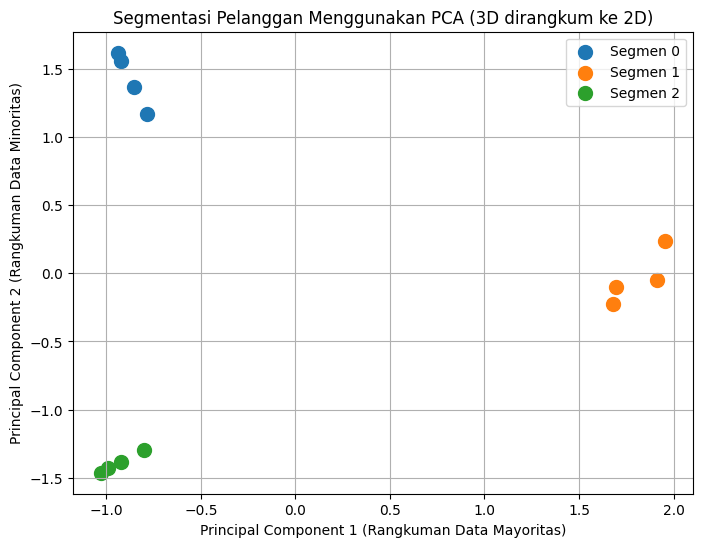

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

data_pelanggan = {
    'Usia': [19, 21, 20, 23, 58, 60, 62, 55, 30, 32, 31, 35],
    'Pendapatan': [15, 16, 15, 18, 80, 85, 82, 78, 120, 130, 125, 140],
    'Skor_Belanja': [30, 35, 32, 40, 15, 10, 12, 18, 90, 95, 88, 92]
}
df_pelanggan = pd.DataFrame(data_pelanggan)

preprocessor = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2))
])

df_scaled = preprocessor.fit_transform(df_pelanggan)

best_k = 1
best_score = 0
rentang_k = range(2, 6)

for k in rentang_k:
    model = KMeans(n_clusters=k, random_state=42, n_init='auto')
    label = model.fit_predict(df_scaled)
    score = silhouette_score(df_scaled, label)

    if score > best_score:
        best_score = score
        best_k = k

master_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', KMeans(n_clusters=best_k, random_state=42, n_init='auto'))
])

cluster_labels = master_pipeline.fit_predict(df_pelanggan)
df_pelanggan['Segmen'] = cluster_labels

print(f"Jumlah Cluster Terbaik (K): {best_k} dengan Silhouette Score: {best_score:.4f}")
print(df_pelanggan)

plt.figure(figsize=(8, 6))

for i in range(best_k):
    baris_segmen = df_pelanggan['Segmen'] == i
    plt.scatter(df_scaled[baris_segmen, 0], df_scaled[baris_segmen, 1], 
                s=100, label=f'Segmen {i}')

plt.title('Segmentasi Pelanggan Menggunakan PCA (3D dirangkum ke 2D)')
plt.xlabel('Principal Component 1 (Rangkuman Data Mayoritas)')
plt.ylabel('Principal Component 2 (Rangkuman Data Minoritas)')
plt.legend()
plt.grid(True)
plt.show()

In [6]:
pca_model = preprocessor.named_steps['pca']
print("\nRasio Informasi yang Dipertahankan:", pca_model.explained_variance_ratio_)


Rasio Informasi yang Dipertahankan: [0.54935312 0.44899512]
